# Análisis de una cartera en varias divisas

El ejemplo combina un activo denominado en EUR y otro en USD. Para que se ejecute sin red, el proveedor ECB usa una respuesta CSV oficial capturada de la [API de datos del ECB](https://data.ecb.europa.eu/help/api/data-examples); el cuaderno reemplaza el transporte HTTP por esa respuesta. En uso normal, `ECBExchangeRateSource` consulta el endpoint diario. `Portfolio` invierte el par EUR/USD para expresar los precios USD en EUR. La serie manual permite comparar rentabilidades locales y de reporte.

Los tipos ECB son referencias informativas, no precios de ejecución de un bróker. Las fechas diarias no permiten fijar un corte intradía común entre mercados.

In [1]:
"""Ejemplo reproducible de análisis diario de una cartera en varias divisas."""

import math
from io import BytesIO
from unittest.mock import patch

import pandas as pd
from IPython.display import display as show

from quantfolio import (
    ECBExchangeRateSource,
    ExchangeRates,
    MonteCarloParameters,
    Portfolio,
    PriceSeries,
)

START = "2026-10-26"
# Límite exclusivo para mantener fijo el periodo del ejemplo.
END = "2026-11-06"
DEMO_SOURCE = "Serie didáctica"

In [2]:
asset_dates = pd.DatetimeIndex(
    ["2026-10-26", "2026-10-27", "2026-10-28", "2026-10-29", "2026-10-30"]
)
euro_asset = PriceSeries(
    ticker="ACTIVO_EUR",
    prices=pd.Series([80.0, 81.2, 80.5, 82.0, 83.1], index=asset_dates),
    source=DEMO_SOURCE,
    quote_currency="EUR",
)
dollar_asset = PriceSeries(
    ticker="ACTIVO_USD",
    prices=pd.Series([100.0, 103.0, 101.0, 104.0, 105.0], index=asset_dates),
    source=DEMO_SOURCE,
    quote_currency="USD",
)

In [3]:
# Valores de referencia publicados por el ECB para este intervalo.
ecb_csv = (
    "TIME_PERIOD,OBS_VALUE\n"
    "2026-10-26,1.1188\n"
    "2026-10-27,1.1150\n"
    "2026-10-28,1.1133\n"
    "2026-10-29,1.1130\n"
    "2026-10-30,1.1172\n"
    "2026-11-02,1.1216\n"
    "2026-11-03,1.1179\n"
    "2026-11-04,1.1267\n"
    "2026-11-05,1.1224\n"
)
ecb_source = ECBExchangeRateSource()
with patch("quantfolio.sources.ecb.urlopen", return_value=BytesIO(ecb_csv.encode())):
    eur_usd = ecb_source.get_prices("FX:EUR/USD", start=START, end=END)
exchange_rates = ExchangeRates([eur_usd])
print(f"Proveedor: {eur_usd.source}")
print(f"Par: {eur_usd.ticker}; unidad de cotización: {eur_usd.quote_currency}")
show(eur_usd.prices.tail())

Proveedor: ECB reference rates
Par: FX:EUR/USD; unidad de cotización: USD


2026-10-30    1.1172
2026-11-02    1.1216
2026-11-03    1.1179
2026-11-04    1.1267
2026-11-05    1.1224
Name: FX:EUR/USD, dtype: float64

In [4]:
portfolio = Portfolio(
    assets={euro_asset.ticker: euro_asset, dollar_asset.ticker: dollar_asset},
    weights={euro_asset.ticker: 0.5, dollar_asset.ticker: 0.5},
    reporting_currency="EUR",
    exchange_rates=exchange_rates,
)
local_returns = dollar_asset.prices.pct_change().dropna()
reporting_prices = portfolio.get_reporting_prices()
reporting_returns = reporting_prices[dollar_asset.ticker].pct_change().dropna()
return_comparison = pd.DataFrame(
    {
        "Rentabilidad local USD": local_returns,
        "Rentabilidad convertida EUR": reporting_returns,
    }
)
show(return_comparison.style.format("{:.2%}"))

,Rentabilidad local USD,Rentabilidad convertida EUR
2026-10-27 00:00:00,3.00%,3.35%
2026-10-28 00:00:00,-1.94%,-1.79%
2026-10-29 00:00:00,2.97%,3.00%
2026-10-30 00:00:00,0.96%,0.58%


## Introducir tipos de cambio manuales

Una serie `FX:USD/EUR` almacena euros por cada dólar. Al usar un par directo, no hace falta solicitarlo a un proveedor. El ejemplo calculado de forma independiente da EUR 90,00 → EUR 104,50 y una rentabilidad del 16,1111 %.

In [5]:
manual_dates = asset_dates[:2]
manual_asset = PriceSeries(
    ticker="ACTIVO_USD_MANUAL",
    prices=pd.Series([100.0, 110.0], index=manual_dates),
    source=DEMO_SOURCE,
    quote_currency="USD",
)
manual_rate = PriceSeries(
    ticker="FX:USD/EUR",
    prices=pd.Series([0.90, 0.95], index=manual_dates),
    source="Tipo de cambio manual",
    quote_currency="EUR",
)
manual_portfolio = Portfolio(
    assets={manual_asset.ticker: manual_asset},
    weights={manual_asset.ticker: 1.0},
    reporting_currency="EUR",
    exchange_rates=ExchangeRates([manual_rate]),
)
manual_reporting_prices = manual_portfolio.get_reporting_prices()[manual_asset.ticker]
manual_returns = manual_reporting_prices.pct_change().dropna()
expected_prices = [90.0, 104.5]
if list(manual_reporting_prices) != expected_prices:
    msg = "La conversión manual no coincide con el cálculo EUR esperado."
    raise ValueError(msg)
expected_return = expected_prices[1] / expected_prices[0] - 1.0
conversion_tolerance = 1e-12
if not math.isclose(
    float(manual_returns.iloc[0]),
    expected_return,
    rel_tol=0.0,
    abs_tol=conversion_tolerance,
):
    msg = "La rentabilidad convertida no coincide con el cálculo esperado."
    raise ValueError(msg)
show(
    pd.DataFrame(
        {
            "Precio local USD": manual_asset.prices,
            "Precio de reporte EUR": manual_reporting_prices,
        }
    )
)
print(f"Rentabilidad local USD: {manual_asset.prices.pct_change().dropna().iloc[0]:.4%}")
print(f"Rentabilidad de reporte EUR: {manual_returns.iloc[0]:.4%}")

,Precio local USD,Precio de reporte EUR
2026-10-26,100.0,90.0
2026-10-27,110.0,104.5


Rentabilidad local USD: 10.0000%
Rentabilidad de reporte EUR: 16.1111%


,asset,asset_date,source_currency,reporting_currency,pair,source,rate_date,age_days,rate,applied_rate,inverted,carried_forward
0,ACTIVO_EUR,2026-10-26,EUR,EUR,-,No requerida,2026-10-26,0,1.0000,1.000000,False,False
1,ACTIVO_EUR,2026-10-27,EUR,EUR,-,No requerida,2026-10-27,0,1.0000,1.000000,False,False
2,ACTIVO_EUR,2026-10-28,EUR,EUR,-,No requerida,2026-10-28,0,1.0000,1.000000,False,False
3,ACTIVO_EUR,2026-10-29,EUR,EUR,-,No requerida,2026-10-29,0,1.0000,1.000000,False,False
4,ACTIVO_EUR,2026-10-30,EUR,EUR,-,No requerida,2026-10-30,0,1.0000,1.000000,False,False
5,ACTIVO_USD,2026-10-26,USD,EUR,FX:EUR/USD,ECB reference rates,2026-10-26,0,1.1188,0.893815,True,False
6,ACTIVO_USD,2026-10-27,USD,EUR,FX:EUR/USD,ECB reference rates,2026-10-27,0,1.1150,0.896861,True,False
7,ACTIVO_USD,2026-10-28,USD,EUR,FX:EUR/USD,ECB reference rates,2026-10-28,0,1.1133,0.898230,True,False
8,ACTIVO_USD,2026-10-29,USD,EUR,FX:EUR/USD,ECB reference rates,2026-10-29,0,1.1130,0.898473,True,False
9,ACTIVO_USD,2026-10-30,USD,EUR,FX:EUR/USD,ECB reference rates,2026-10-30,0,1.1172,0.895095,True,False


# Informe de la cartera

## 1. Composición

| Activo | Divisa local | Peso |
|---|---|---:|
| ACTIVO_EUR | EUR | 50.00% |
| ACTIVO_USD | USD | 50.00% |

- Divisa de reporte: EUR.

## 2. Métricas históricas

| Métrica | Valor |
|---|---:|
| Rentabilidad media diaria | 1.1227% |
| Volatilidad diaria | 1.7734% |
| Rentabilidad anualizada aproximada | 282.93% |
| Volatilidad anualizada | 28.15% |
| Error estándar de la rentabilidad anualizada | 223.45% |
| IC 95% de la rentabilidad anualizada | -155.04% - 720.90% |
| Rentabilidad geométrica (CAGR) | 1518.72% |
| Deriva del logaritmo usada por Monte Carlo | 278.42% |
| Crecimiento mediano implícito (exp(m)-1) | 1518.72% |
| Máxima caída histórica | -1.33% |
| Ratio de Sharpe (rf=0.00%) | 10.05 |
| VaR histórico diario (95%) | 0.98% |
| CVaR histórico diario (95%) | 1.33% |

_Un VaR o CVaR negativo indica que el cuantil de la cola es una ganancia._

_La simulación usa la deriva del logaritmo; su mediana crece a exp(m)-1, no a la rentabilidad

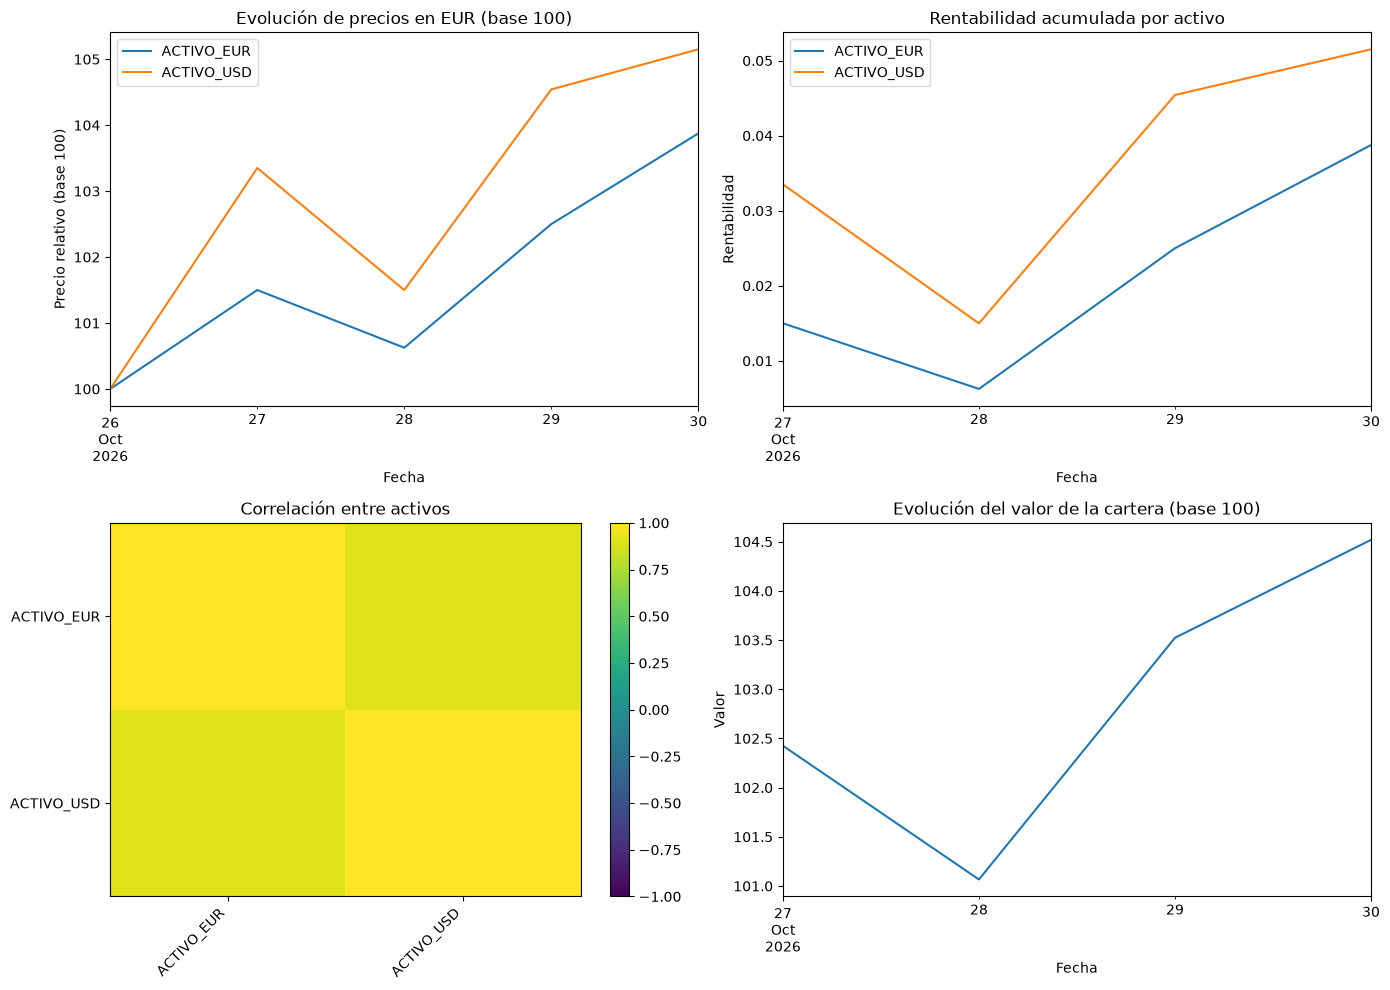

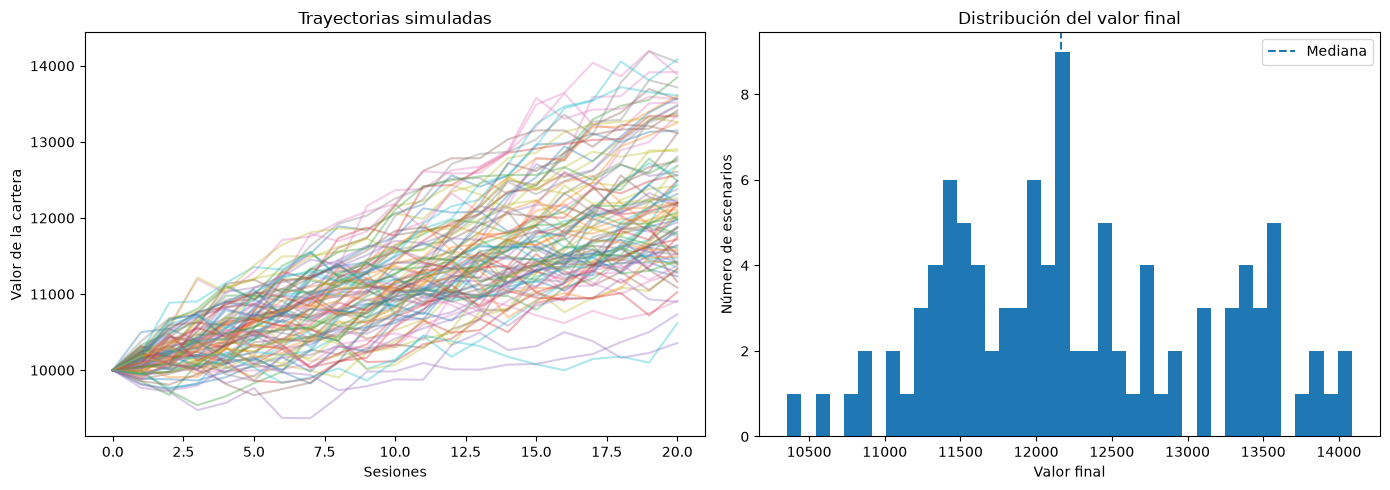

In [6]:
show(portfolio.currency_conversion_diagnostics().head(10))
print(portfolio.report())
simulations = portfolio.simulate_monte_carlo(MonteCarloParameters(n_paths=100, horizon=20, seed=42))
portfolio.plots_report()
portfolio.plot_simulation(simulations)